# Customer Churn Prediction – Telco Dataset
**Pipeline:** cleaning → EDA → preprocessing (one-hot + scaling inside a `Pipeline`) → imbalance-aware models → 5-fold CV → threshold tuning → explainability → export.

Run from the `notebook/` folder (data is read from `../data/`).

## 1. Imports

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 2. Load data

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 3. Cleaning
`TotalCharges` has 11 blank strings – all belong to customers with `tenure = 0` (brand-new, nothing billed yet), so the correct value is **0**, not a dropped row.

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Blank TotalCharges rows:", df['TotalCharges'].isna().sum())
print("Their tenure values:", df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

Blank TotalCharges rows: 11
Their tenure values: [0]


In [6]:
customer_ids = df['customerID'].copy()      # keep for the predictions export
df = df.drop('customerID', axis=1)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df.shape)
print("Churn rate: %.1f%%  |  majority-class baseline accuracy: %.1f%%" %
      (df['Churn'].mean()*100, (1-df['Churn'].mean())*100))

(7043, 20)
Churn rate: 26.5%  |  majority-class baseline accuracy: 73.5%


## 4. Exploratory analysis

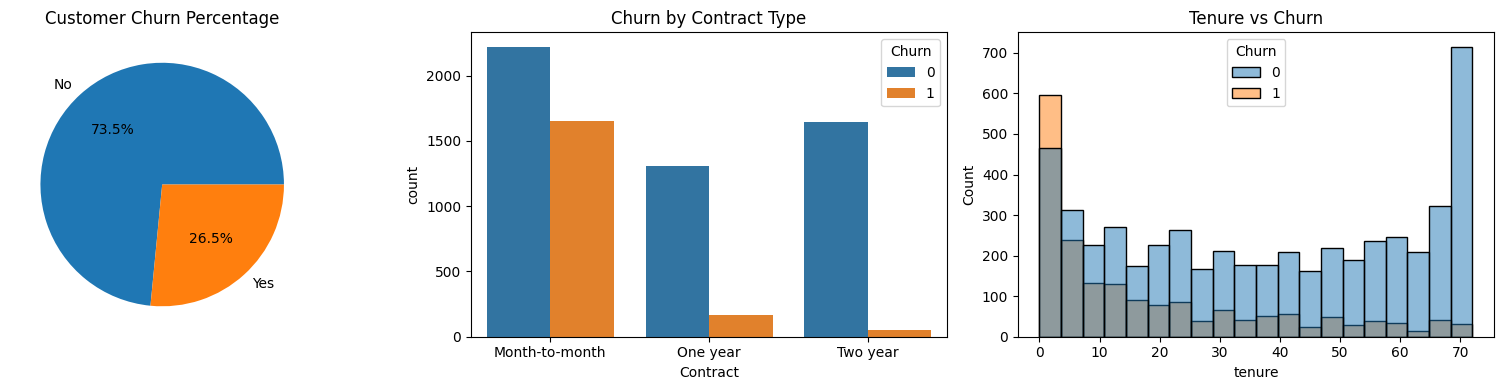

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df['Churn'].value_counts(normalize=True).sort_index().mul(100).plot(
    kind='pie', autopct='%1.1f%%', labels=['No', 'Yes'], ax=ax[0], ylabel='')
ax[0].set_title("Customer Churn Percentage")
sns.countplot(x='Contract', hue='Churn', data=df, ax=ax[1]); ax[1].set_title("Churn by Contract Type")
sns.histplot(data=df, x='tenure', hue='Churn', bins=20, ax=ax[2]); ax[2].set_title("Tenure vs Churn")
plt.tight_layout(); plt.show()

## 5. Preprocessing
- **Numeric** → `StandardScaler`
- **Categorical** → `OneHotEncoder` (the old `LabelEncoder` imposed a fake order on nominal features such as `PaymentMethod`)

Both live inside a `Pipeline`, so they are fit only on training folds → no leakage.

In [8]:
X = df.drop('Churn', axis=1)
y = df['Churn']

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


## 6. Models (imbalance-aware)
Only ~27% of customers churn, so each model is told to weight the minority class more: `class_weight='balanced'` (LR, RF) and `scale_pos_weight` (XGBoost).

In [9]:
spw = (y == 0).sum() / (y == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                            random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                             subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                             eval_metric='logloss', random_state=RANDOM_STATE),
}
pipelines = {name: Pipeline([('pre', preprocessor), ('clf', m)]) for name, m in models.items()}

## 7. 5-fold stratified cross-validation
The models score almost the same, so a single split can't separate them. Accuracy is misleading on imbalanced data → compare **ROC-AUC, PR-AUC, recall, precision, F1**.

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in pipelines.items():
    r = cross_validate(pipe, X, y, cv=cv,
                       scoring=['roc_auc', 'average_precision', 'recall', 'precision', 'f1'])
    rows.append({'Model': name,
                 **{k[5:]: round(v.mean(), 3) for k, v in r.items() if k.startswith('test_')}})
cv_results = pd.DataFrame(rows).rename(columns={'average_precision': 'pr_auc'}).set_index('Model')
cv_results

,roc_auc,pr_auc,recall,precision,f1
Model,,,,,
Logistic Regression,0.845,0.655,0.803,0.513,0.626
Random Forest,0.821,0.605,0.470,0.627,0.537
XGBoost,0.847,0.665,0.798,0.521,0.630


## 8. Fit all models on the training split

In [11]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
probs = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in pipelines.items()}

## 9. ROC and Precision-Recall curves (test set)

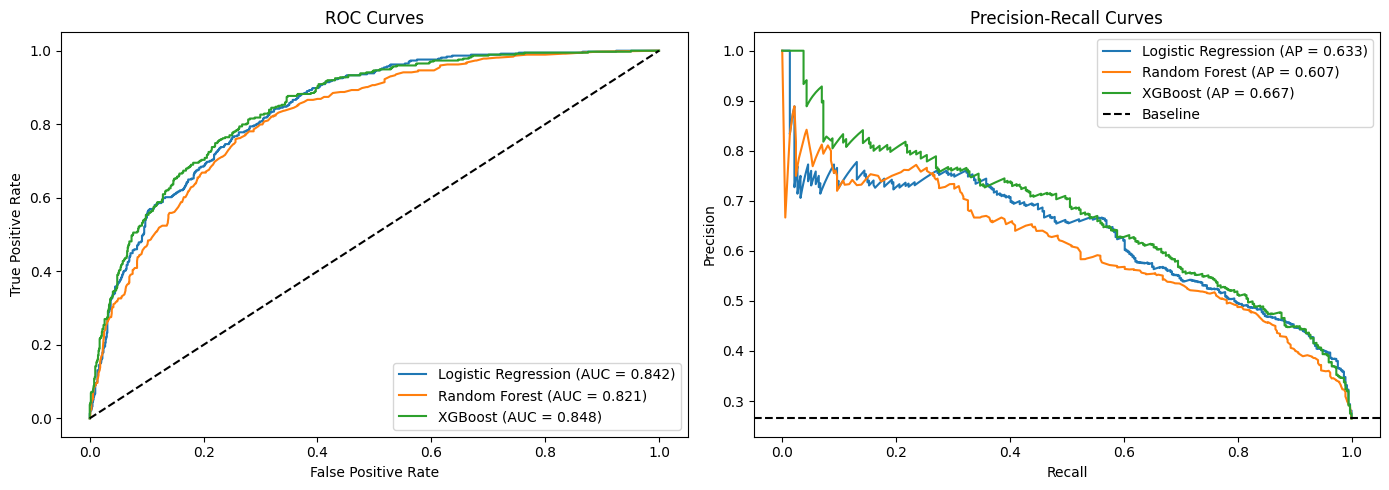

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curves")
ax[1].axhline(y_test.mean(), color='k', ls='--', label='Baseline'); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curves")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 10. Threshold tuning
The default 0.5 cutoff is not optimal. Pick the threshold that maximises F1 on the PR curve (swap in a cost-based rule if you know the retention cost vs. customer value).

> Note: the threshold is chosen on the test split here for simplicity; in production, choose it on a validation split or via CV predictions.

In [13]:
best_name = 'Logistic Regression'          # simplest model, ~tied with XGBoost on ROC-AUC
best_pipe = pipelines[best_name]
best_prob = probs[best_name]

pr, rc, th = precision_recall_curve(y_test, best_prob)
f1 = 2 * pr * rc / (pr + rc + 1e-9)
best_t = th[f1[:-1].argmax()]
print(f"Best-F1 threshold: {best_t:.3f}\n")

for t, label in [(0.5, "Default threshold 0.5"), (best_t, f"Tuned threshold {best_t:.3f}")]:
    print("=== " + label + " ===")
    print(classification_report(y_test, (best_prob >= t).astype(int), digits=3))

Best-F1 threshold: 0.544

=== Default threshold 0.5 ===
              precision    recall  f1-score   support

           0      0.902     0.722     0.802      1035
           1      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

=== Tuned threshold 0.544 ===
              precision    recall  f1-score   support

           0      0.898     0.750     0.817      1035
           1      0.525     0.765     0.622       374

    accuracy                          0.754      1409
   macro avg      0.711     0.757     0.720      1409
weighted avg      0.799     0.754     0.766      1409



## 11. Confusion matrices (tuned threshold)

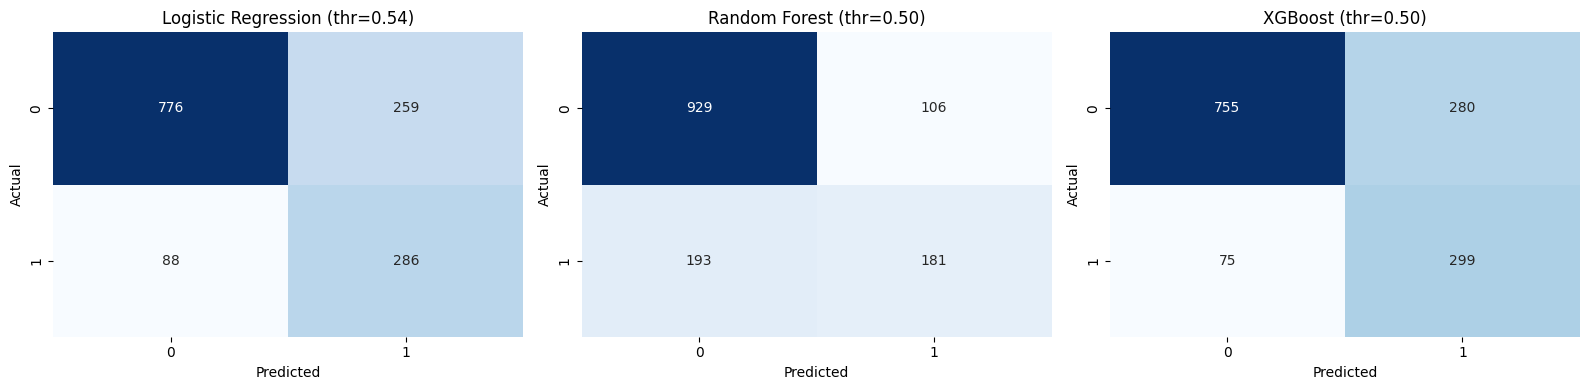

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, p) in zip(ax, probs.items()):
    t = best_t if name == best_name else 0.5
    sns.heatmap(confusion_matrix(y_test, (p >= t).astype(int)), annot=True, fmt='d', cmap='Blues', ax=a, cbar=False)
    a.set(xlabel="Predicted", ylabel="Actual", title=f"{name} (thr={t:.2f})")
plt.tight_layout(); plt.show()

## 12. Top churn drivers

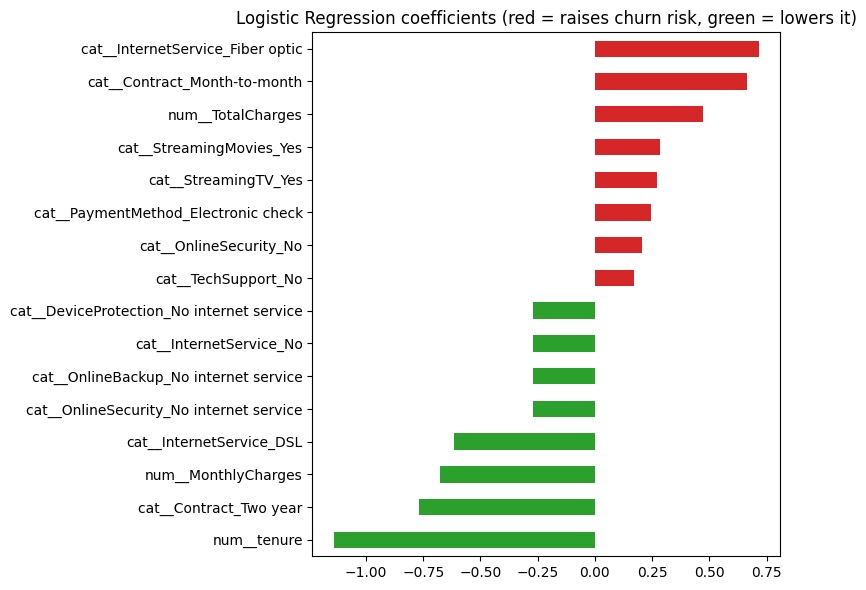

In [15]:
feat_names = best_pipe.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(best_pipe.named_steps['clf'].coef_[0], index=feat_names).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])
plt.figure(figsize=(8, 6))
top.plot(kind='barh', color=['tab:green' if v < 0 else 'tab:red' for v in top])
plt.title("Logistic Regression coefficients (red = raises churn risk, green = lowers it)")
plt.tight_layout(); plt.show()

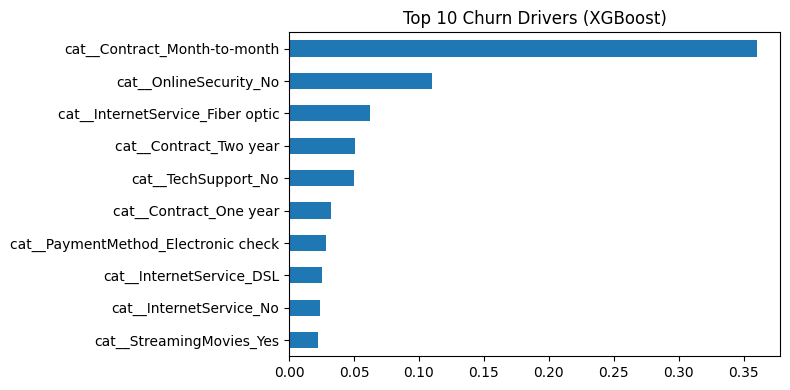

In [16]:
xgb_pipe = pipelines['XGBoost']
imp = pd.Series(xgb_pipe.named_steps['clf'].feature_importances_,
                index=xgb_pipe.named_steps['pre'].get_feature_names_out()).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
imp[::-1].plot(kind='barh'); plt.title("Top 10 Churn Drivers (XGBoost)")
plt.tight_layout(); plt.show()

## 13. Top-decile lift (business view)

In [17]:
res = pd.DataFrame({'actual': y_test.values, 'prob': best_prob}).sort_values('prob', ascending=False).reset_index(drop=True)
res['decile'] = pd.qcut(res.index, 10, labels=range(1, 11))
lift = res.groupby('decile')['actual'].agg(['sum', 'mean'])
lift['pct_of_all_churners'] = lift['sum'] / res['actual'].sum() * 100
print(f"Top 10% highest-risk customers contain {lift.loc[1,'pct_of_all_churners']:.1f}% of all churners "
      f"(churn rate {lift.loc[1,'mean']*100:.1f}% vs {y_test.mean()*100:.1f}% overall).")
lift.round(3)

Top 10% highest-risk customers contain 28.6% of all churners (churn rate 75.9% vs 26.5% overall).


,sum,mean,pct_of_all_churners
decile,,,
1,107,0.759,28.610
2,79,0.560,21.123
3,57,0.404,15.241
4,48,0.340,12.834
5,35,0.248,9.358
6,24,0.171,6.417
7,15,0.106,4.011
8,6,0.043,1.604
9,1,0.007,0.267


## 14. Export predictions (original, unscaled features + customerID) and the trained pipeline

In [18]:
import os
os.makedirs("../data", exist_ok=True)
out = X_test.copy()
out.insert(0, 'customerID', customer_ids.loc[X_test.index].values)
out['Actual_Churn'] = y_test.values
out['Churn_Probability'] = best_prob
out['Predicted_Churn'] = (best_prob >= best_t).astype(int)
out.sort_values('Churn_Probability', ascending=False).to_csv("../data/churn_predictions.csv", index=False)

joblib.dump({'pipeline': best_pipe, 'threshold': float(best_t)}, "churn_model.joblib")
out.sort_values('Churn_Probability', ascending=False).head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn
3380,5178-LMXOP,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.937978,1
6866,0295-PPHDO,Male,0,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.926779,1
2631,6861-XWTWQ,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.925977,1
6365,8884-ADFVN,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.922239,1
4585,1069-XAIEM,Female,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.920495,1


## 15. Using the saved model on new customers
`churn_model.joblib` holds the full pipeline, so raw customer rows (same columns as `X`) can be scored directly:
```python
bundle = joblib.load("churn_model.joblib")
p = bundle['pipeline'].predict_proba(new_df)[:, 1]
flag = (p >= bundle['threshold']).astype(int)
```